# 4. Training a network

Training has two steps:

1. simulate a training set from the prior (parallel, saved in chunks, resumable),
2. train NPE with a neural spline flow.

The paper's networks used 500 000 simulations (~250 CPU-hours) and up to 1000 epochs. Here a tiny
version for the no-foreground model shows the workflow in a few minutes; the result is not a useful network.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from gwbf_foregrounds import NOFG, data, posterior, train

In [2]:
train.DEFAULTS            # settings of the paper's full network

{'num_simulations': 500000,
 'hidden_features': 300,
 'num_transforms': 10,
 'batch_size': 256,
 'learning_rate': 1e-05,
 'max_epochs': 1000,
 'stop_after_epochs': 30,
 'validation_fraction': 0.1}

In [3]:
files = train.simulate_training_set("nofg", num_simulations=600, chunk_size=100,
                                    out_dir="training_demo", n_workers=6)
theta, x = train.load_training_set("nofg", out_dir="training_demo")
print(theta.shape, x.shape)

[nofg] 0/6 chunks already done, 6 to simulate in training_demo/nofg


  1/6 chunks  4.3 min  (~22 min left)


  2/6 chunks  4.3 min  (~9 min left)


  3/6 chunks  4.3 min  (~4 min left)


  4/6 chunks  4.3 min  (~2 min left)


  5/6 chunks  4.3 min  (~1 min left)


  6/6 chunks  4.3 min  (~0 min left)


torch.Size([600, 3]) torch.Size([600, 5910])


In [4]:
post = train.train("nofg", out_dir="training_demo", save_dir="trained_demo",
                   max_epochs=20, stop_after_epochs=5, learning_rate=1e-3, verbose=False)
print(open("trained_demo/nofg/model_info.txt").read())

 Training neural network. Epochs trained: 1

 Training neural network. Epochs trained: 2

 Training neural network. Epochs trained: 3

 Training neural network. Epochs trained: 4

 Training neural network. Epochs trained: 5

 Neural network successfully converged after 6 epochs.

model: nofg  (Strings + instrument noise, no foregrounds; BOS)
parameters: logGmu, A_p, A_acc
fixed: {}
physics settings: {'VOS_or_BOS': 'BOS'}
prior:
  logGmu: ('uniform', -18.0, -9.0)
  A_p: ('uniform', 12.0, 18.0)
  A_acc: ('uniform', 2.4000000000000004, 3.5999999999999996)
simulations: 600   feature dimension: 5910
density estimator: NSF (sbi NPE), no embedding net
  hidden_features: 300
  num_transforms: 10
  batch_size: 256
  learning_rate: 0.001
  max_epochs: 20
  stop_after_epochs: 5
  validation_fraction: 0.1
epochs trained: 6   best validation loss: 19.6744
training time: 0.00 h   device: cpu
sbi version: 0.25.0



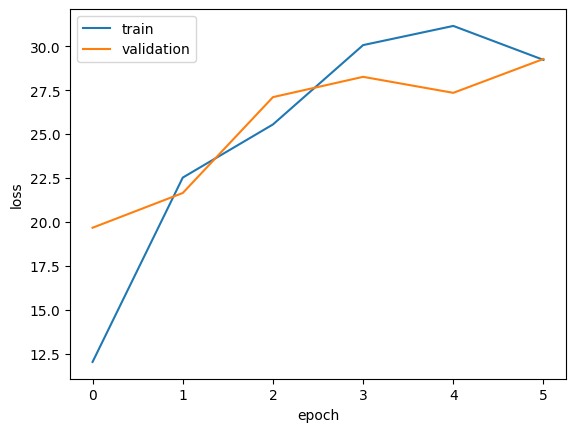

In [5]:
h = np.load("trained_demo/nofg/history.npz")
plt.plot(h["train_losses"], label="train"); plt.plot(h["valid_losses"], label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend();

The trained posterior is used exactly like the released ones:

In [6]:
p = posterior.load_posterior("trained_demo/nofg/posterior.pkl", NOFG.param_names)
ds = data.simulate("nofg", logGmu=-12, seed=0)
s = posterior.sample(p, ds, n=2000)
print("log10 Gmu: median", np.median(s[:, 0]).round(2), "(truth -12; a tiny network is not accurate)")

log10 Gmu: median -12.89 (truth -12; a tiny network is not accurate)


## Full-scale training

```bash
gwbf-fg train --model full --simulate-only     # 500 000 simulations; resumable, e.g. as a cluster job
gwbf-fg train --model full --train-only        # NPE training with the paper's settings
```

In [7]:
import shutil; shutil.rmtree("training_demo"); shutil.rmtree("trained_demo")